# WEATHER PREDICTION

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as ms 
from statsmodels.tsa.stattools import adfuller
import plotly.graph_objects as go

%matplotlib inline
print(" Done setup" )

 Done setup


In [3]:
df = pd.read_csv("seattle-weather.csv")
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## data discriptions

### shape of the data

In [4]:
df.shape

(1461, 6)

### descibe the data

In [5]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,1461,1461,2012-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precipitation,1461.0,NaN,NaN,NaN,3.029432,6.680194,0.0,0.0,0.0,2.8,55.9
temp_max,1461.0,NaN,NaN,NaN,16.439083,7.349758,-1.6,10.6,15.6,22.2,35.6
temp_min,1461.0,NaN,NaN,NaN,8.234771,5.023004,-7.1,4.4,8.3,12.2,18.3
wind,1461.0,NaN,NaN,NaN,3.241136,1.437825,0.4,2.2,3.0,4.0,9.5
weather,1461,5,rain,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### information of data

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   str    
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   str    
dtypes: float64(4), str(2)
memory usage: 88.0 KB


### null values
- informarin, change date column into datetime from str.

In [7]:
df.isna().sum()

date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

<Axes: >

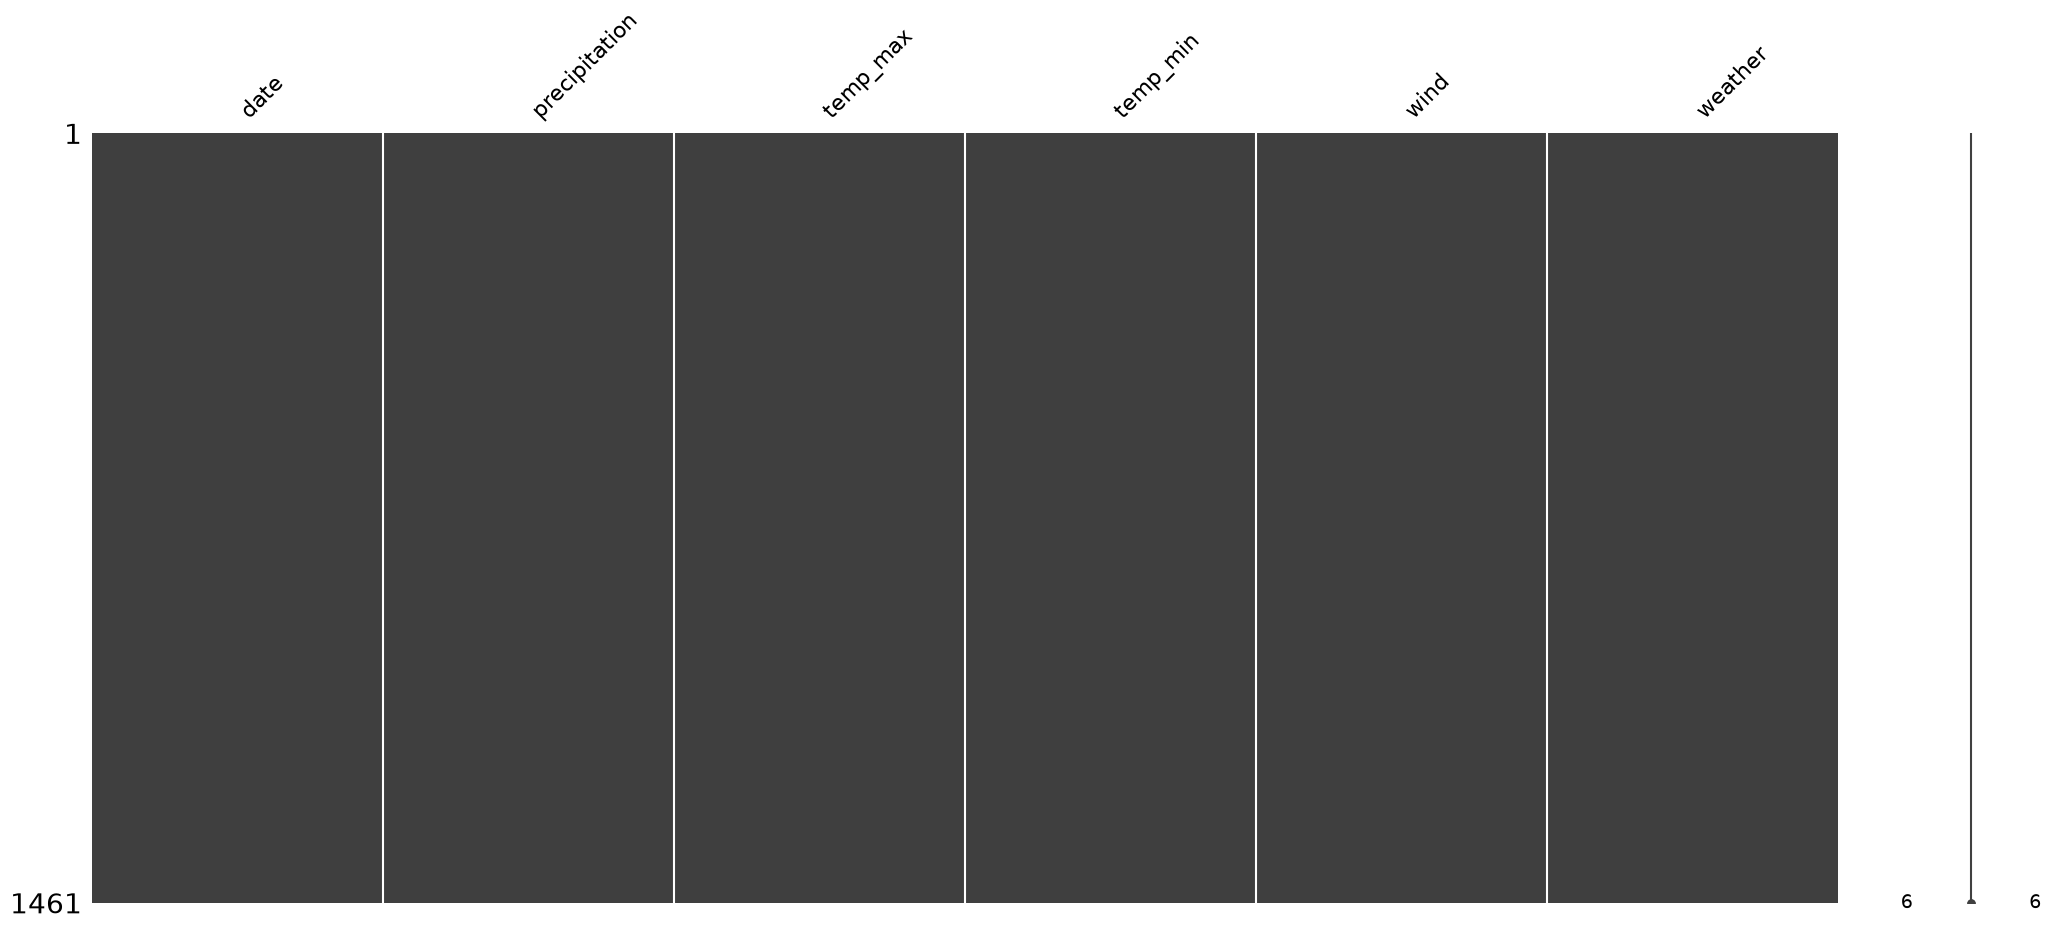

In [8]:
ms.matrix(df)

## Time-Series Analysis

### Analysing seasonality, trend, and autoregression 

### converted date column into date-time frame

In [9]:

## year wise
# conveting date column into datetime
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

#defined function 
def to_datetime(X):
    return pd.DataFrame(pd.to_datetime(X.iloc[:,0]))

trf = ColumnTransformer([
    ('datetime-data',FunctionTransformer(to_datetime), [0])
], remainder='passthrough')

#fit transfrom
transformed_data = trf.fit_transform(df)
data = pd.DataFrame(transformed_data, columns=df.columns)
data.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


### analysing precipitation, temp_max, temp_min and wind over the year in seattle



#### for max_temperature checking for stationarity

In [33]:
import plotly.graph_objects as go
import pandas as pd

# 1. Ensure the date column is explicitly parsed as datetime and set as index
data['date'] = pd.to_datetime(data['date'])
data = data.set_index('date')

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_max'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

In [11]:
# Group your stationary series by year and check mean & std


result = adfuller(data['temp_max'].dropna())

print(f"ADF Test Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4e}")
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")

ADF Test Statistic: -2.4292
p-value: 1.3366e-01
Critical Values:
   1%: -3.4349
   5%: -2.8635
   10%: -2.5678


- our critical value is 5%, adf test shows stats greater than 5%
- N not -> 'the max temperature is non-stationarity, meaning std, mean, variance, nothing remained constant over the year
- N alternate -> ' the max temp is stationariy  / no non-statinariy

##### original case
-> we fail to reject N0 meaning we are somehow accepting the data is non-stationary. Since, p_value > 5%

### achieving stationarity 
-> diff

In [35]:
import plotly.graph_objects as go
import pandas as pd

# 1. Ensure the date column is explicitly parsed as datetime and set as index

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_max'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

In [13]:
result = adfuller(stationary_temp.dropna())

print(f"ADF Test Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4e}")
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")

ADF Test Statistic: -15.6132
p-value: 1.7694e-28
Critical Values:
   1%: -3.4349
   5%: -2.8635
   10%: -2.5678


#### interpreting diff
-> since, first we have removed the first nan value fro the data. 
-> we are rejecting N0

### min temp

In [14]:
# adf for min temp 
min_result = adfuller(data['temp_min'].dropna()) 
print(f" ADF test statictic: {min_result[0]:.4f}")
print(f"p-values: {min_result[1]:.4e}")
print(f"Critical values:")
for key, value in min_result[4].items():
    print(f" {key} : {value:.4f}")               

 ADF test statictic: -2.6056
p-values: 9.1841e-02
Critical values:
 1% : -3.4349
 5% : -2.8635
 10% : -2.5678


In [36]:

# Ensure datetime index and sort
data.index = pd.to_datetime(data.index)
data = data.sort_index()

# Calculate rolling statistics (e.g., a 30-day window)
window_size = 30
rolling_mean = data['temp_min'].rolling(window=window_size).mean()
rolling_std = data['temp_min'].rolling(window=window_size).std()

# Create interactive Plotly figure
fig = go.Figure()

# 1. Raw Data
fig.add_trace(go.Scatter(
    x=data.index, y=data['temp_min'], 
    name='Original Min Temp', 
    line=dict(color='lightblue', width=1), opacity=0.7
))

# 2. Rolling Mean
fig.add_trace(go.Scatter(
    x=data.index, y=rolling_mean, 
    name=f'{window_size}-Day Rolling Mean', 
    line=dict(color='red', width=2)
))

# 3. Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=data.index, y=rolling_std, 
    name=f'{window_size}-Day Rolling Std', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration with a secondary Y-axis for standard deviation
fig.update_layout(
    title_text="<b>Stationarity Check: Rolling Mean & Std (Min Temperature)</b>",
    xaxis_title="Date",
    yaxis_title="Temperature (°)",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

#### after diff

In [16]:
min_result_diff = data['temp_min'].diff().dropna()
result_diff = adfuller(min_result_diff.dropna())
print(f"ADF statistic result: {result_diff[0]:.4}")

print(f"p-value: {result_diff[1]:.4f}")
print(" Critical values")

for key, value in result_diff[4].items():
    print(f" {key} : {value:.4f}")

ADF statistic result: -16.47
p-value: 0.0000
 Critical values
 1% : -3.4349
 5% : -2.8635
 10% : -2.5678


In [40]:
import plotly.graph_objects as go
import pandas as pd

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_min'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

### wind 

In [18]:
wind_original = data['wind'].dropna()
wind_result = adfuller(wind_original.dropna())
print(f"ADF statistic: {wind_result[0]:.4f}")
print(f"p-value: {wind_result[1]:.4e}")
print("Critical Value: ")
for key, value in wind_result[4].items():
    print(f" {key} : {value}")

ADF statistic: -24.5074
p-value: 0.0000e+00
Critical Value: 
 1% : -3.434836872962171
 5% : -2.863521656701378
 10% : -2.567825016419591


In [41]:


# 1. Make the series stationary by applying first-order differencing (or seasonal differencing)
# This removes the upward/downward trends and flattens out the seasonal waves

# 2. Calculate rolling statistics on the stationary series (e.g., 30-day window)
window_size = 30
rolling_mean_stat = data['wind'].rolling(window=window_size).mean()
rolling_std_stat = data['wind'].rolling(window=window_size).std()

# 3. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data (Looks like random noise bouncing around zero)
fig.add_trace(go.Scatter(
    x=data.index, y=data['wind'], 
    name='wind', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean (Should look like a flat line near zero)
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation (Should stay relatively stable and flat)
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration showing flat, stable bounds
fig.update_layout(
    title_text="original",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

#### diff wind

In [20]:
wind_result_diff = data['wind'].diff().dropna()

In [43]:
import plotly.graph_objects as go
import pandas as pd

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['wind'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

* since, min, max temp and wind needs to be differencing 

## model training data with diff

In [22]:
data_diff = df.copy()
data_diff_ = trf.fit_transform(data_diff)
data_diff = pd.DataFrame(data_diff_, columns=df.columns)
data_diff.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1461 non-null   datetime64[us]
 1   precipitation  1461 non-null   object        
 2   temp_max       1461 non-null   object        
 3   temp_min       1461 non-null   object        
 4   wind           1461 non-null   object        
 5   weather        1461 non-null   str           
dtypes: datetime64[us](1), object(4), str(1)
memory usage: 73.8+ KB


### Creating new column with suffix _diff

In [23]:
data_diff[['temp_max_diff', 'temp_min_diff', 'wind_diff']] = data_diff[['temp_max', 'temp_min', 'wind']].diff()
data_diff = data_diff.dropna()

print(data_diff.shape)

(1460, 9)


In [24]:
data_diff.drop(columns=['temp_max', 'temp_min', 'wind'], inplace=True)
data_diff.head()

,date,precipitation,weather,temp_max_diff,temp_min_diff,wind_diff
1,2012-01-02,10.9,rain,-2.2,-2.2,-0.2
2,2012-01-03,0.8,rain,1.1,4.4,-2.2
3,2012-01-04,20.3,rain,0.5,-1.6,2.4
4,2012-01-05,1.3,rain,-3.3,-2.8,1.4
5,2012-01-06,2.5,rain,-4.5,-0.6,-3.9


### OneHotEncoding for weather column

In [25]:

from sklearn.preprocessing import OneHotEncoder

# 1. Set up the ColumnTransformer to encode 'weather' and pass through the rest
trf2 = ColumnTransformer([
    ('weather-encoder', OneHotEncoder(sparse_output=False, drop='first'), ['weather'])
], remainder='passthrough')

# 2. Fit and transform the data_diff DataFrame
transformed_array = trf2.fit_transform(data_diff)

# 3. Get the raw feature names generated by the transformer
raw_column_names = trf2.get_feature_names_out()

# 4. Clean up the names by stripping the prefixes ('weather-encoder__' and 'remainder__')
clean_column_names = [
    col.replace('weather-encoder__', '').replace('remainder__', '') 
    for col in raw_column_names
]

# 5. Create a new DataFrame with the transformed data and clean column names
encoded_weather_df = pd.DataFrame(transformed_array, columns=clean_column_names, index=data_diff.index)

# 6. Replace or assign back to data_diff cleanly (avoiding duplicate original columns)
data_diff = encoded_weather_df

# Inspect the final result
data_diff.head()

,weather_fog,weather_rain,weather_snow,weather_sun,date,precipitation,temp_max_diff,temp_min_diff,wind_diff
1,0.0,1.0,0.0,0.0,2012-01-02,10.9,-2.2,-2.2,-0.2
2,0.0,1.0,0.0,0.0,2012-01-03,0.8,1.1,4.4,-2.2
3,0.0,1.0,0.0,0.0,2012-01-04,20.3,0.5,-1.6,2.4
4,0.0,1.0,0.0,0.0,2012-01-05,1.3,-3.3,-2.8,1.4
5,0.0,1.0,0.0,0.0,2012-01-06,2.5,-4.5,-0.6,-3.9


### correlation wiht target value 'precipitation'

In [26]:
data_diff.corrwith(data_diff['precipitation'])

weather_fog     -0.123723
weather_rain     0.467043
weather_snow     0.111321
weather_sun     -0.400943
date             0.013769
precipitation    1.000000
temp_max_diff   -0.063171
temp_min_diff    0.036553
wind_diff        0.146917
dtype: float64

In [27]:
data_diff.corr()

,weather_fog,weather_rain,weather_snow,weather_sun,date,precipitation,temp_max_diff,temp_min_diff,wind_diff
weather_fog,1.000000,-0.241178,-0.036708,-0.240843,0.189268,-0.123723,0.031558,-0.086331,-0.012723
weather_rain,-0.241178,1.000000,-0.119124,-0.781574,-0.096545,0.467043,-0.142429,0.112597,0.145834
weather_snow,-0.036708,-0.119124,1.000000,-0.118958,-0.161229,0.111321,-0.018996,-0.015178,-0.017277
weather_sun,-0.240843,-0.781574,-0.118958,1.000000,0.094952,-0.400943,0.147586,-0.047500,-0.132740
date,0.189268,-0.096545,-0.161229,0.094952,1.000000,0.013769,-0.005963,-0.008177,0.001314
precipitation,-0.123723,0.467043,0.111321,-0.400943,0.013769,1.000000,-0.063171,0.036553,0.146917
temp_max_diff,0.031558,-0.142429,-0.018996,0.147586,-0.005963,-0.063171,1.000000,0.225165,-0.007324
temp_min_diff,-0.086331,0.112597,-0.015178,-0.047500,-0.008177,0.036553,0.225165,1.000000,0.261444
wind_diff,-0.012723,0.145834,-0.017277,-0.132740,0.001314,0.146917,-0.007324,0.261444,1.000000


### correlation heatmap and ms

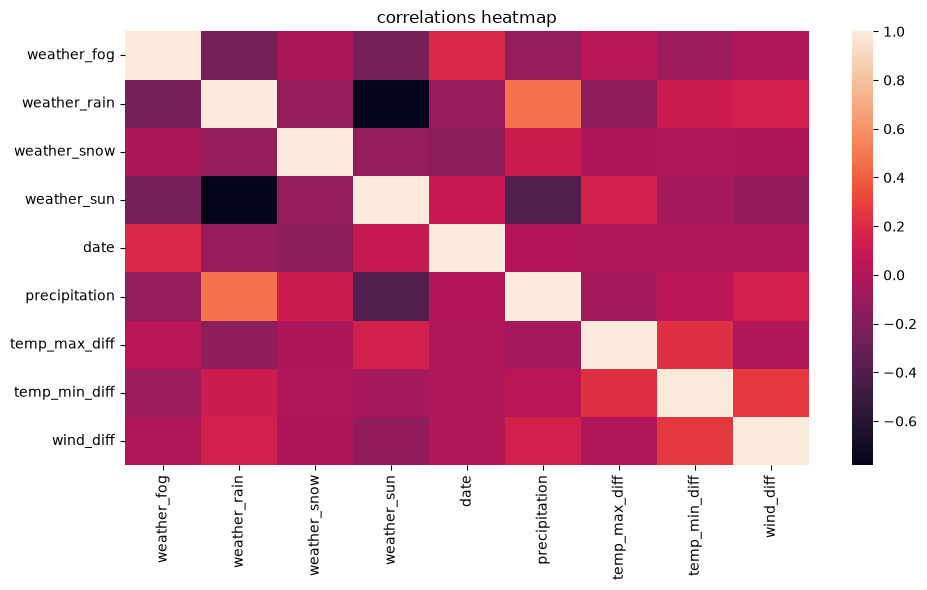

In [28]:
plt.figure(figsize=(10, 6))
sns.heatmap(data_diff.corr())
plt.title("correlations heatmap")
plt.tight_layout()
plt.show()

### converting data into year, month and days

In [29]:
data_diff['year'] = data_diff['date'].dt.year
data_diff['month'] = data_diff['date'].dt.month
data_diff['day'] = data_diff['date'].dt.day
data_diff.drop(columns=['date'], inplace=True)

## ivar and dvar

In [30]:
endog = data_diff['precipitation']
exogs = data_diff[['weather_fog', 'weather_rain', 'weather_snow', 'weather_sun',
       'temp_max_diff', 'temp_min_diff', 'wind_diff', 'year', 'month', 'day']]

In [31]:
X.columns

NameError: name 'X' is not defined

In [ ]:
print("--- EXOG DATATYPES ---")
print(exogs.dtypes)

print("\n--- ENDOG DATATYPE ---")
print(endog.dtype)

--- EXOG DATATYPES ---
weather_fog      object
weather_rain     object
weather_snow     object
weather_sun      object
temp_max_diff    object
temp_min_diff    object
wind_diff        object
year              int32
month             int32
day               int32
dtype: object

--- ENDOG DATATYPE ---
object


In [ ]:
# 1. Convert all columns in exogs to numeric, forcing any corrupted/string values to NaN
exogs_clean = exogs.apply(pd.to_numeric, errors='coerce')

# 2. Also ensure your endog ('precipitation') is numeric
endog_clean = pd.to_numeric(endog, errors='coerce')

# 3. Drop any resulting NaNs to ensure data alignment and cleanliness
model_data = pd.concat([endog_clean, exogs_clean], axis=1).dropna()

endog_final = model_data.iloc[:, 0]
exogs_final = model_data.iloc[:, 1:]

## Applying ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
p,d,q = 1,1,1
model = ARIMA(endog = endog_final, exog=exogs_final, order=(p,d,q))
model_fit = model.fit()

#summary
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:          precipitation   No. Observations:                 1460
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4612.499
Date:                Fri, 30 Oct 2026   AIC                           9250.998
Time:                        00:23:30   BIC                           9319.710
Sample:                             0   HQIC                          9276.631
                               - 1460                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
weather_fog      -1.3548      3.496     -0.387      0.698      -8.207       5.498
weather_rain      5.2008      3.601      1.444      0.149      -1.858      12.259
weather_snow      7.4462      3.756     

/home/anuj/anaconda3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


#### again trying ot train model 

In [ ]:
endog = data_diff['precipitation']
exogs = data_diff[[ 'weather_rain', 'weather_snow',
        'temp_min_diff', 'wind_diff']]
exogs_clean = exogs.apply(pd.to_numeric, errors='coerce')

# 2. Also ensure your endog ('precipitation') is numeric
endog_clean = pd.to_numeric(endog, errors='coerce')

# 3. Drop any resulting NaNs to ensure data alignment and cleanliness
model_data = pd.concat([endog_clean, exogs_clean], axis=1).dropna()

endog_final = model_data.iloc[:, 0]
exogs_final = model_data.iloc[:, 1:]
exogs_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 1 to 1460
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   weather_rain   1460 non-null   float64
 1   weather_snow   1460 non-null   float64
 2   temp_min_diff  1460 non-null   float64
 3   wind_diff      1460 non-null   float64
dtypes: float64(4)
memory usage: 45.8 KB


In [ ]:
from sklearn.preprocessing import  StandardScaler, MinMaxScaler
trf3 = ColumnTransformer([
    ('scaler', MinMaxScaler(), ['temp_min_diff', 'wind_diff'])
], remainder='passthrough')

# 3. Fit and transform the feature matrix
transformed_exog = trf3.fit_transform(exogs_final)

# 4. Extract and clean column names
raw_names = trf3.get_feature_names_out()
clean_names = [
    col.replace('scaler__', '').replace('remainder__', '') 
    for col in raw_names
]

# 5. Reconstruct the clean, scaled exog DataFrame preserving the index
exog_scaled = pd.DataFrame(transformed_exog, columns=clean_names, index=exogs_final.index)

# 6. Refit the ARIMAX model
p, d, q = 1, 1, 1
model = ARIMA(endog=endog_final, exog=exog_scaled, order=(p, d, q))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:          precipitation   No. Observations:                 1460
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4613.766
Date:                Fri, 30 Oct 2026   AIC                           9241.531
Time:                        00:23:31   BIC                           9278.530
Sample:                             0   HQIC                          9255.334
                               - 1460                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
temp_min_diff    -1.7630      1.037     -1.700      0.089      -3.795       0.269
wind_diff         4.7738      1.126      4.241      0.000       2.567       6.980
weather_rain      5.9964      0.465     

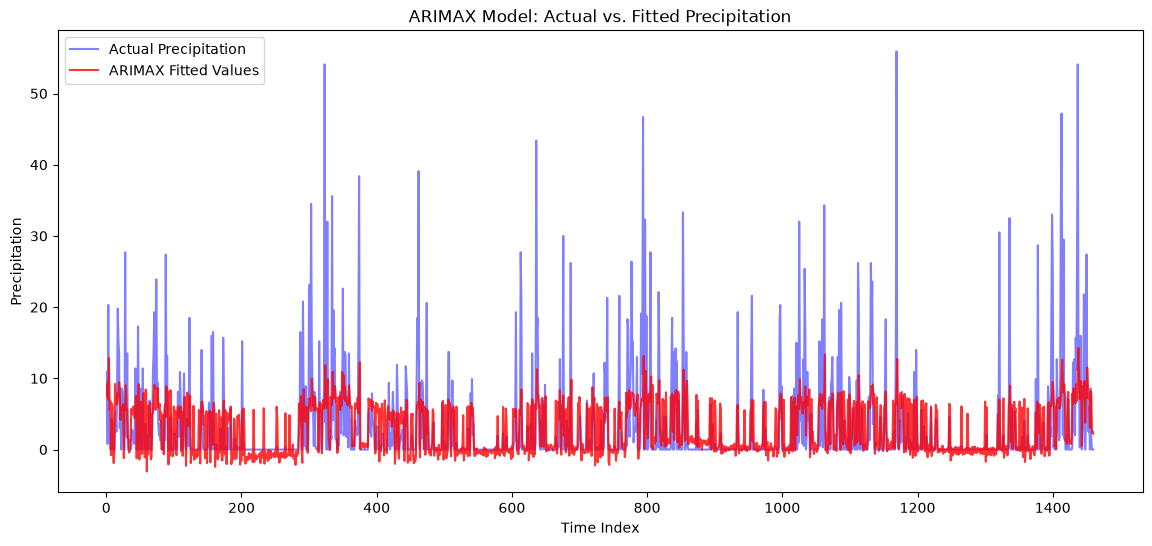

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(endog_final.index, endog_final, label='Actual Precipitation', color='blue', alpha=0.5)
plt.plot(endog_final.index, model_fit.fittedvalues, label='ARIMAX Fitted Values', color='red', alpha=0.8)

plt.title('ARIMAX Model: Actual vs. Fitted Precipitation')
plt.xlabel('Time Index')
plt.ylabel('Precipitation')
plt.legend()
plt.show()